# 03 U-Net (Lab 9 + Assignment 6)

Segment buildings, trees, and open ground. Two models:
- **v1**: plain U-Net in torch, 10 epochs (the first run). Kept for comparison: `data/models/unet_v1_plain.pt`
- **v2**: U-Net with an ImageNet ResNet-34 encoder (segmentation-models-pytorch), longer training, Dice loss, more augmentation. This is the final model: `data/models/unet.pt`

Training ran as a script, not in this notebook (it is long, and runs better in the background):

```bash
conda activate geoai
python musa6950/train_unet.py --tag a_r34 --minutes 40      # the final recipe, short run
python musa6950/train_unet.py --tag b_r34_ndvi --ndvi --minutes 20   # + NDVI as a 5th band
python musa6950/train_unet.py --tag c_r34_ce --dice 0 --minutes 20   # cross entropy only
python musa6950/train_unet.py --tag d_plain --kind plain --no-pretrained --lr 1e-3 --minutes 20   # plain U-Net, new recipe
python musa6950/train_unet.py --tag v2_r34 --epochs 16 --minutes 95 --patience 5   # final model, copied to data/models/unet.pt
```

This notebook loads the saved weights and does the checks:
1. Leakage check (no test box in train or validation, no overlap)
2. Ablation table (validation only)
3. Test-time flips / turns (validation only)
4. Test counties, once: v1 vs v2 on the same pixels
5. How high can it go? (label noise ceiling)
6. Figures

**Inputs**
- `data/raw/6950/naip/`, `data/raw/6950/labels/`
- `data/models/unet.pt`, `unet_v1_plain.pt`, `unet_*_log.csv`, `unet_*_summary.json`

**Output**
- `data/processed/6950_metrics_unet.json` (v2) and `6950_metrics_unet_v1.json` (v1)
- `docs/figures/03_training_curve.png`, `03_unet_confusion.png`, `03_example_prediction.png`, `03_test_urban.png`, `03_test_suburban.png`, `03_test_rural.png`

Use the geoai env.

In [1]:
import sys
import json
import time
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
import shapely
import torch
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from scipy import ndimage

ROOT = Path.cwd().parents[1] if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "shared"))
sys.path.insert(0, str(ROOT / "musa6950"))
from common import RAW, OUT
from unet import CLASSES, load_model, predict_array
from train_unet import split_boxes, load, confusion, scores, VAL_COUNTIES
R6 = RAW / "6950"
FIG = ROOT / "musa6950" / "docs" / "figures"
MODELS = ROOT / "data" / "models"
device = "mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu"

boxes = split_boxes()      # same split as before: seed 42, 7 held-back train counties
print("val counties:", VAL_COUNTIES)
print(boxes.groupby(["role", "stratum"]).size().unstack())

val counties: ['42001', '42009', '42011', '42021', '42099', '42109', '42117']
stratum  rural  suburban  urban
role                           
test         7        10     10
train       40        39     43
val          7        10      7


## 1. Leakage check

- Test = Cumberland (42041) + Centre (42027). No test county may show up in train or validation
- Validation counties may not show up in train
- No two boxes in different roles may overlap on the ground (uses the real image extents)

In [2]:
role_counties = boxes.groupby("role").county.apply(set)
assert not role_counties["test"] & (role_counties["train"] | role_counties["val"]), "test county in train/val"
assert not role_counties["val"] & role_counties["train"], "val county in train"
assert role_counties["test"] == {"42041", "42027"}
parts = []
for _, b in boxes.iterrows():
    with rasterio.open(R6 / "naip" / f"{b.GEOID}.tif") as s:
        parts.append(gpd.GeoDataFrame({"GEOID": [b.GEOID], "role": [b.role]}, geometry=[shapely.box(*s.bounds)], crs=s.crs).to_crs(5070))
ext = gpd.GeoDataFrame(pd.concat(parts, ignore_index=True), crs=5070)
j = gpd.sjoin(ext, ext, predicate="intersects")
j = j[j.GEOID_left < j.GEOID_right].copy()
j["overlap_m2"] = [ext.geometry[a].intersection(ext.geometry[b]).area for a, b in zip(j.index, j.index_right)]
print(j[["GEOID_left", "role_left", "GEOID_right", "role_right", "overlap_m2"]].round(0).to_string(index=False))
cross = j[j.role_left != j.role_right]
assert len(cross) == 0, "boxes in different roles overlap"
print(f"\nOK: {len(boxes)} boxes, no box shared between roles, no overlap across roles.")
print("Overlaps inside one role:", len(j), "pairs. A test-test overlap only counts some test pixels twice, it is not leakage")
leak = {"test_counties": sorted(role_counties["test"]), "val_counties": VAL_COUNTIES, "cross_role_overlaps": int(len(cross)),
        "same_role_overlaps": j[["GEOID_left", "GEOID_right", "role_left", "overlap_m2"]].round(0).to_dict("records")}

 GEOID_left role_left GEOID_right role_right  overlap_m2
42043023000     train 42043023100      train    150253.0
42041013104      test 42041013200       test     92213.0

OK: 173 boxes, no box shared between roles, no overlap across roles.
Overlaps inside one role: 2 pairs. A test-test overlap only counts some test pixels twice, it is not leakage


## 2. Ablation (validation only)

- Validation = every labeled pixel of the 24 validation boxes, predicted in 512 px windows like the test
- v1 is scored here the same way, so the numbers compare (its old 0.682 was on 256 px tiles)
- Each run: epochs of 400 steps x 12 crops of 384 px, on a Mac (MPS)
- The short runs were stopped by a time cap (20 or 40 min), so they are also compared at the same epoch (epoch 3), where the learning rate is the same
- An EfficientNet-B2 encoder was planned but skipped to stay in the time budget

In [3]:
v1, v1meta = load_model(MODELS / "unet_v1_plain.pt", device)
val = boxes[boxes.role == "val"]
cm_v1_val = np.zeros((4, 4), np.int64)
for g in val.GEOID:
    img, lab = load(g)
    cm_v1_val += confusion(predict_array(v1, img, v1meta["mean"], v1meta["std"], device), lab)
v1_val = scores(cm_v1_val)

rows = [{"run": "v1 plain U-Net, 10 epochs (old recipe)", "val_miou": v1_val["miou"], "val_miou_epoch3": np.nan, "epochs": 10, **v1_val["iou"], "minutes": 44.9}]
names = {"a_r34": "ResNet-34, CE + Dice, new augmentation", "b_r34_ndvi": "  + NDVI 5th band",
         "c_r34_ce": "  cross entropy only (no Dice)", "d_plain": "plain U-Net, new recipe (no pretrained encoder)",
         "v2_r34": "final: ResNet-34 recipe, 16 epoch schedule"}
for tag, name in names.items():
    f = MODELS / f"unet_{tag}_log.csv"
    if not f.exists():
        continue
    lg = pd.read_csv(f)
    b = lg.loc[lg.val_miou.idxmax()]
    e3 = lg.loc[lg.epoch == 3, "val_miou"]
    rows.append({"run": name, "val_miou": b.val_miou, "val_miou_epoch3": e3.iloc[0] if len(e3) else np.nan, "epochs": len(lg),
                 **{c: b[f"val_iou_{c}"] for c in CLASSES}, "minutes": round(lg.minutes.iloc[-1], 1)})
ablation = pd.DataFrame(rows)
print(ablation.round(4).to_string(index=False))

                                            run  val_miou  val_miou_epoch3  epochs  other  building   tree   open  minutes
         v1 plain U-Net, 10 epochs (old recipe)    0.6892              NaN      10 0.6340    0.5618 0.8074 0.7538     44.9
         ResNet-34, CE + Dice, new augmentation    0.7289           0.7106       9 0.6787    0.6425 0.8190 0.7754     44.3
                                + NDVI 5th band    0.7040           0.6862       3 0.6525    0.6000 0.8066 0.7571     26.8
                   cross entropy only (no Dice)    0.7090           0.7046       5 0.6544    0.6074 0.8118 0.7624     22.6
plain U-Net, new recipe (no pretrained encoder)    0.6688           0.6688       3 0.6271    0.5323 0.7844 0.7316     21.9
     final: ResNet-34 recipe, 16 epoch schedule    0.7358           0.7069      14 0.6846    0.6600 0.8191 0.7795     95.1


/opt/anaconda3/envs/geoai/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


final model: v2_r34 | best epoch 14 | val mIoU 0.7358 | NDVI False
training time: 95.1 min, 14 epochs


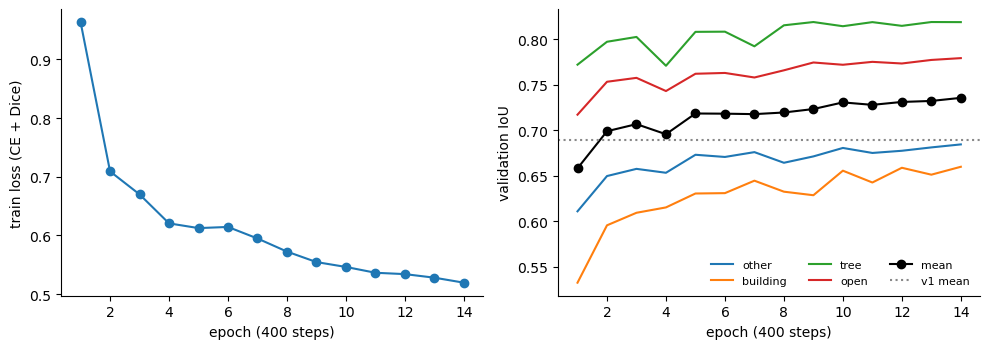

In [4]:
model, meta = load_model(MODELS / "unet.pt", device)
TAG = meta["args"]["tag"]
log = pd.read_csv(MODELS / f"unet_{TAG}_log.csv")
print("final model:", TAG, "| best epoch", meta["epoch"], "| val mIoU", meta["val_miou"], "| NDVI", meta["ndvi"])
print(f"training time: {log.minutes.iloc[-1]:.1f} min, {len(log)} epochs")
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].plot(log.epoch, log.train_loss, "o-")
ax[0].set_xlabel("epoch (400 steps)"); ax[0].set_ylabel("train loss (CE + Dice)")
for c in CLASSES:
    ax[1].plot(log.epoch, log[f"val_iou_{c}"], "-", label=c)
ax[1].plot(log.epoch, log.val_miou, "ko-", label="mean")
ax[1].axhline(v1_val["miou"], color="#888", ls=":", label="v1 mean")
ax[1].set_xlabel("epoch (400 steps)"); ax[1].set_ylabel("validation IoU"); ax[1].legend(frameon=False, ncol=3, fontsize=8)
for a in ax:
    a.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(FIG / "03_training_curve.png", dpi=110)
plt.show()

## 3. Test-time flips and turns, and a tree offset (validation only)

- Predict each window 8 times (4 turns x flip), undo the turn, average the class probabilities
- Keep it only if it helps on validation
- Tree offset: the model calls a bit less tree than the label. Add a log offset to the tree class, try 0 to 1.5 on validation, keep the best mIoU
  - Found after the first test run: on the Cumberland check lots (notebook 05) v2 called much less tree than the label. The offset is set on validation only

In [5]:
OFFSETS = [0, 0.25, 0.5, 0.75, 1.0, 1.5]
cm_plain = np.zeros((4, 4), np.int64)
cm_off = {b: np.zeros((4, 4), np.int64) for b in OFFSETS}
t1 = time.time()
for g in val.GEOID:
    img, lab = load(g)
    lp = np.log(predict_array(model, img, meta["mean"], meta["std"], device, ndvi=meta["ndvi"], proba=True, tta=True).astype(np.float32) + 1e-6)
    for b in OFFSETS:
        q = lp.copy(); q[2] += b
        cm_off[b] += confusion(q.argmax(0).astype(np.uint8), lab)
    cm_plain += confusion(predict_array(model, img, meta["mean"], meta["std"], device, ndvi=meta["ndvi"]), lab)
s_plain, s_tta = scores(cm_plain), scores(cm_off[0])
TTA = s_tta["miou"] > s_plain["miou"]
print(f"val mIoU, one pass {s_plain['miou']:.4f} | 8 flips/turns {s_tta['miou']:.4f} | use TTA: {TTA} ({time.time() - t1:.0f} s)")
off_tab = pd.DataFrame([{"tree_offset": b, "val_miou": scores(c)["miou"], "tree_iou": scores(c)["iou"]["tree"],
                         "pred_tree / label_tree": round(c[:, 2].sum() / c[2].sum(), 3)} for b, c in cm_off.items()])
print(off_tab.to_string(index=False))
TREE_OFF = float(off_tab.loc[off_tab.val_miou.idxmax(), "tree_offset"])
BIAS = [0.0, 0.0, TREE_OFF, 0.0]
s_final_val = scores(cm_off[TREE_OFF])
print("tree offset:", TREE_OFF, "| val mIoU", s_final_val["miou"])
ck = torch.load(MODELS / "unet.pt", map_location="cpu", weights_only=False)   # save the offset with the weights, notebook 05 reads it
ck["class_bias"], ck["tta"] = BIAS, bool(TTA)
torch.save(ck, MODELS / "unet.pt")

val mIoU, one pass 0.7358 | 8 flips/turns 0.7402 | use TTA: True (120 s)
 tree_offset  val_miou  tree_iou  pred_tree / label_tree
        0.00    0.7402    0.8218                   0.941
        0.25    0.7417    0.8247                   0.968
        0.50    0.7420    0.8252                   0.996
        0.75    0.7409    0.8231                   1.027
        1.00    0.7383    0.8179                   1.059
        1.50    0.7284    0.7995                   1.130
tree offset: 0.5 | val mIoU 0.742


## 4. Test counties, once

- Cumberland + Centre, 27 boxes, every pixel whose label is not 255
- v1 and v2 on the same pixels
- Per class: IoU, precision (of pixels called X, share that are X), recall (of X pixels, share found)
- Secondary score: ignore a 1 pixel band along every label edge (see section 5)

In [6]:
def edge_band(lab):
    """True where a pixel's 3 x 3 neighbourhood holds another class (a 1 pixel band on each side of an edge)."""
    return ndimage.maximum_filter(lab, 3) != ndimage.minimum_filter(lab, 3)


def full_scores(cm):
    s = scores(cm)
    tp = np.diag(cm).astype(float)
    s["precision"] = dict(zip(CLASSES, (tp / cm.sum(0)).round(4).tolist()))
    s["recall"] = dict(zip(CLASSES, (tp / cm.sum(1)).round(4).tolist()))
    return s


test = boxes[boxes.role == "test"]
STRATA = ["urban", "suburban", "rural"]
cm = {m: np.zeros((4, 4), np.int64) for m in ["v1", "v2"]}
cm_by = {(m, s): np.zeros((4, 4), np.int64) for m in ["v1", "v2"] for s in STRATA}
cm_core = {m: np.zeros((4, 4), np.int64) for m in ["v1", "v2"]}
SHIFTS = [(dy, dx) for dy in range(-2, 3) for dx in range(-2, 3)]
cm_shift = {k: np.zeros((4, 4), np.int64) for k in SHIFTS}
n_band, err_band, err_all, keep = 0, 0, 0, {}
t1 = time.time()
for _, b in test.iterrows():
    img, lab = load(b.GEOID)
    p1 = predict_array(v1, img, v1meta["mean"], v1meta["std"], device)
    p2 = predict_array(model, img, meta["mean"], meta["std"], device, ndvi=meta["ndvi"], tta=TTA, bias=BIAS)
    band = edge_band(lab)
    core = np.where(band, 255, lab).astype(np.uint8)
    for m, p in [("v1", p1), ("v2", p2)]:
        c = confusion(p, lab)
        cm[m] += c; cm_by[(m, b.stratum)] += c
        cm_core[m] += confusion(p, core)
    ok = lab != 255
    n_band += (band & ok).sum(); err_band += (band & ok & (p2 != lab)).sum(); err_all += (ok & (p2 != lab)).sum()
    # does the label line up better with the image if moved by 1-2 pixels? (registration check)
    for dy, dx in SHIFTS:
        cm_shift[(dy, dx)] += confusion(p2[2 + dy:p2.shape[0] - 2 + dy, 2 + dx:p2.shape[1] - 2 + dx], lab[2:-2, 2:-2])
    keep[b.GEOID] = (img, lab, p1, p2)
print(f"test prediction {time.time() - t1:.0f} s, {cm['v2'].sum():,} pixels")

test prediction 152 s, 109,183,195 pixels


In [7]:
res = {m: full_scores(cm[m]) for m in ["v1", "v2"]}
for m in ["v1", "v2"]:
    res[m]["by_group"] = {s: scores(cm_by[(m, s)]) for s in STRATA}
    res[m]["confusion"] = cm[m].tolist()
    res[m]["secondary_miou_edge_band_ignored"] = scores(cm_core[m])["miou"]
    res[m]["secondary_scores_edge_band_ignored"] = scores(cm_core[m])
rows = []
for k in ["miou", "accuracy"]:
    rows.append({"metric": k, "v1": res["v1"][k], "v2": res["v2"][k]})
for c in CLASSES:
    for k in ["iou", "precision", "recall"]:
        rows.append({"metric": f"{c} {k}", "v1": res["v1"][k][c], "v2": res["v2"][k][c]})
for s in STRATA:
    rows.append({"metric": f"{s} mIoU", "v1": res["v1"]["by_group"][s]["miou"], "v2": res["v2"]["by_group"][s]["miou"]})
rows.append({"metric": "mIoU, edge band ignored (secondary)", "v1": res["v1"]["secondary_miou_edge_band_ignored"],
             "v2": res["v2"]["secondary_miou_edge_band_ignored"]})
table = pd.DataFrame(rows)
table["gain"] = table.v2 - table.v1
print(table.round(4).to_string(index=False))

                             metric     v1     v2   gain
                               miou 0.6479 0.6985 0.0506
                           accuracy 0.8235 0.8472 0.0237
                          other iou 0.6012 0.6501 0.0489
                    other precision 0.7408 0.7711 0.0303
                       other recall 0.7614 0.8055 0.0441
                       building iou 0.5432 0.6449 0.1017
                 building precision 0.6213 0.7230 0.1017
                    building recall 0.8120 0.8565 0.0445
                           tree iou 0.6720 0.7060 0.0340
                     tree precision 0.8367 0.8383 0.0016
                        tree recall 0.7734 0.8174 0.0440
                           open iou 0.7753 0.7929 0.0176
                     open precision 0.8772 0.8955 0.0183
                        open recall 0.8696 0.8738 0.0042
                         urban mIoU 0.5880 0.6438 0.0558
                      suburban mIoU 0.6813 0.7324 0.0511
                         rural 

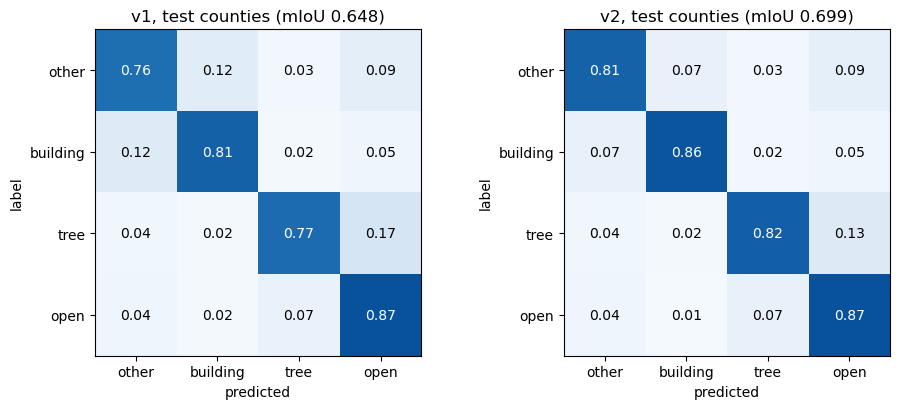

v2 confusion (rows = label, columns = predicted):
             other  building      tree      open
other     12951291   1150097    475804   1500885
building    555338   6393458    176650    339003
tree       1085303    490941  24327266   3859965
open       2204332    808074   4040914  48823874


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(9.6, 4.2))
for a, m in zip(axes, ["v1", "v2"]):
    cmn = cm[m] / cm[m].sum(1, keepdims=True)
    a.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    for i in range(4):
        for k in range(4):
            a.text(k, i, f"{cmn[i, k]:.2f}", ha="center", va="center", color="white" if cmn[i, k] > 0.5 else "black")
    a.set_xticks(range(4), CLASSES); a.set_yticks(range(4), CLASSES)
    a.set_xlabel("predicted"); a.set_ylabel("label")
    a.set_title(f"{m}, test counties (mIoU {res[m]['miou']:.3f})")
plt.tight_layout()
plt.savefig(FIG / "03_unet_confusion.png", dpi=110)
plt.show()
print("v2 confusion (rows = label, columns = predicted):")
print(pd.DataFrame(cm["v2"], index=CLASSES, columns=CLASSES).to_string())

## 5. How high can it go?

The label is not perfect, so 1.0 is not reachable. Three checks:
- **Edge band.** The Chesapeake map is 1 m, put on the 0.6 m NAIP grid by nearest neighbour. Along every edge the true line can be off by about a pixel. How many test pixels sit in a 1 pixel band along an edge, and how many of the errors are there?
- **Registration.** Move the prediction by -2 to +2 pixels against the label. If a shift scores better, the label and the image do not line up exactly
- **Per box spread.** If some boxes score far lower, the label (or the image date) may differ there

In [9]:
shift_miou = pd.Series({k: scores(v)["miou"] for k, v in cm_shift.items()})
best_shift = shift_miou.idxmax()
per_box = pd.DataFrame([{"GEOID": g, "stratum": test.set_index("GEOID").stratum[g], **scores(confusion(p2, lab))}
                        for g, (img, lab, p1, p2) in keep.items()])
ceiling = {"share_pixels_in_edge_band": round(float(n_band / cm["v2"].sum()), 4),
           "share_errors_in_edge_band": round(float(err_band / err_all), 4),
           "miou_shift_0": round(float(shift_miou[(0, 0)]), 4),
           "best_shift_dy_dx": [int(v) for v in best_shift], "miou_best_shift": round(float(shift_miou.max()), 4),
           "per_box_miou_min": round(float(per_box.miou.min()), 4), "per_box_miou_median": round(float(per_box.miou.median()), 4),
           "per_box_miou_max": round(float(per_box.miou.max()), 4)}
print(json.dumps(ceiling, indent=1))
print(shift_miou.unstack().round(4))
print(per_box.sort_values("miou")[["GEOID", "stratum", "miou", "accuracy"]].head(5).to_string(index=False))

{
 "share_pixels_in_edge_band": 0.0989,
 "share_errors_in_edge_band": 0.3228,
 "miou_shift_0": 0.6986,
 "best_shift_dy_dx": [
  -2,
  -1
 ],
 "miou_best_shift": 0.7082,
 "per_box_miou_min": 0.5081,
 "per_box_miou_median": 0.656,
 "per_box_miou_max": 0.7699
}
        -2      -1       0       1       2
-2  0.7050  0.7082  0.7064  0.6997  0.6890
-1  0.7038  0.7069  0.7051  0.6984  0.6877
 0  0.6973  0.7003  0.6986  0.6922  0.6819
 1  0.6864  0.6892  0.6877  0.6819  0.6724
 2  0.6722  0.6748  0.6736  0.6686  0.6600
      GEOID  stratum   miou  accuracy
42027010200 suburban 0.5081    0.8294
42027012300    urban 0.5326    0.7191
42041012300    urban 0.5673    0.7302
42041011500    urban 0.5744    0.7282
42041011200    urban 0.5769    0.7278


## 6. Save + figures

In [10]:
rf = json.loads((OUT / "6950_metrics_rf.json").read_text())
out = dict(res["v2"])
out.update({"model": TAG, "tta": bool(TTA), "n_test_pixels": int(cm["v2"].sum()), "test_boxes": int(len(test)),
            "best_epoch": int(meta["epoch"]), "val_miou": float(meta["val_miou"]), "val_miou_tta": s_tta["miou"],
            "class_bias": BIAS, "val_miou_final": s_final_val["miou"], "tree_offset_grid": off_tab.to_dict("records"),
            "train_minutes": round(float(log.minutes.iloc[-1]), 1), "epochs_run": int(len(log)),
            "class_weights": [round(w, 3) for w in meta["class_weights"]], "args": meta["args"],
            "v1": res["v1"], "v1_val_miou_full_boxes": v1_val["miou"], "ablation": ablation.round(4).to_dict("records"),
            "leakage": leak, "ceiling": ceiling})
(OUT / "6950_metrics_unet.json").write_text(json.dumps(out, indent=1, default=float))
v1_out = dict(res["v1"]); v1_out.update({"n_test_pixels": int(cm["v1"].sum()), "test_boxes": int(len(test))})
(OUT / "6950_metrics_unet_v1.json").write_text(json.dumps(v1_out, indent=1, default=float))
comp = pd.DataFrame({"Random Forest": rf["iou"] | {"mean IoU": rf["miou"], "accuracy": rf["accuracy"]},
                     "U-Net v1": res["v1"]["iou"] | {"mean IoU": res["v1"]["miou"], "accuracy": res["v1"]["accuracy"]},
                     "U-Net v2": res["v2"]["iou"] | {"mean IoU": res["v2"]["miou"], "accuracy": res["v2"]["accuracy"]}})
print(comp.round(3).to_string())

          Random Forest  U-Net v1  U-Net v2
other             0.321     0.601     0.650
building          0.267     0.543     0.645
tree              0.368     0.672     0.706
open              0.485     0.775     0.793
mean IoU          0.360     0.648     0.698
accuracy          0.571     0.824     0.847


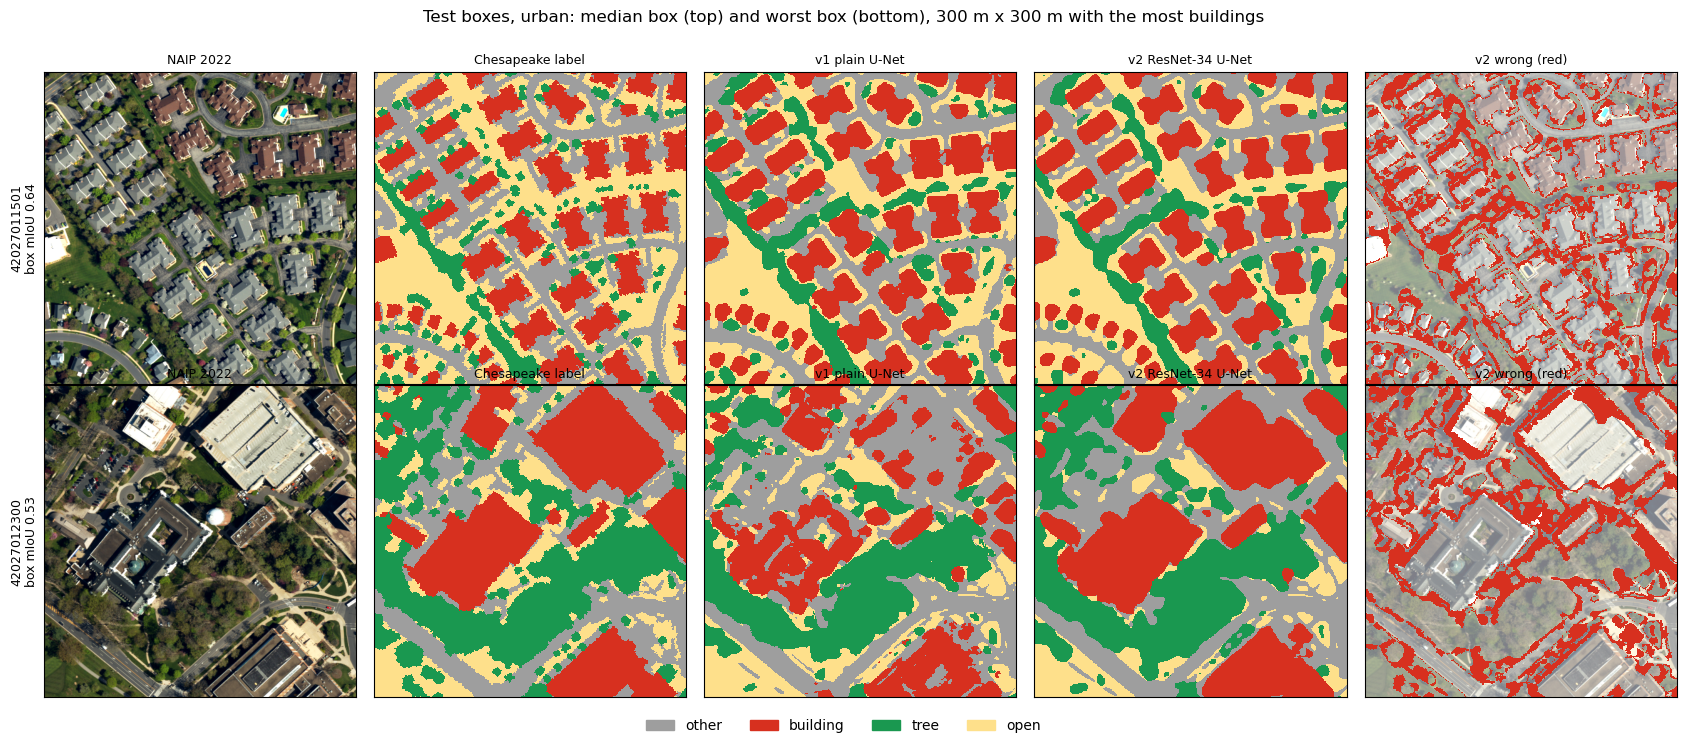

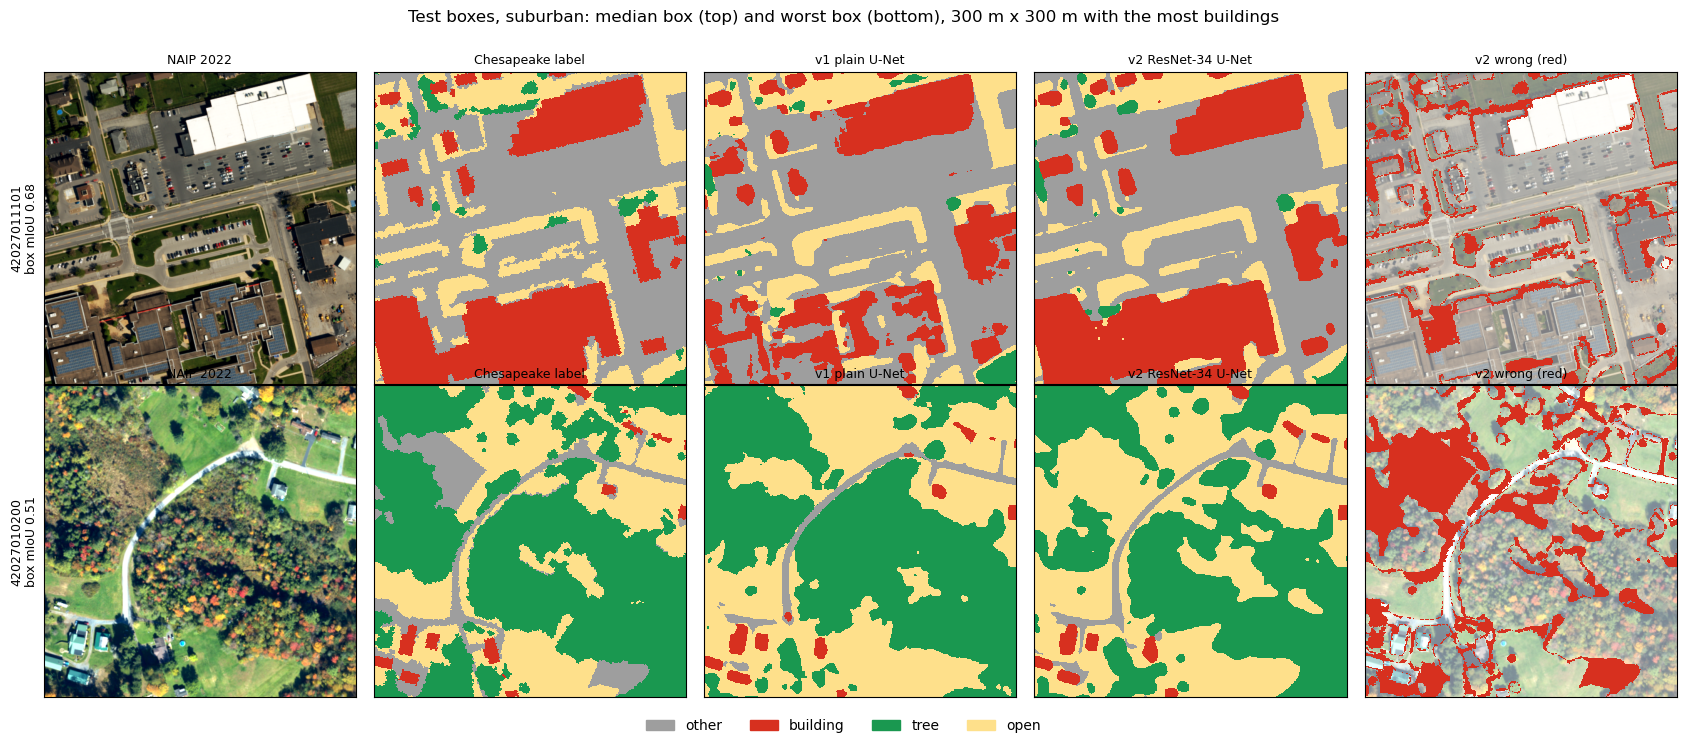

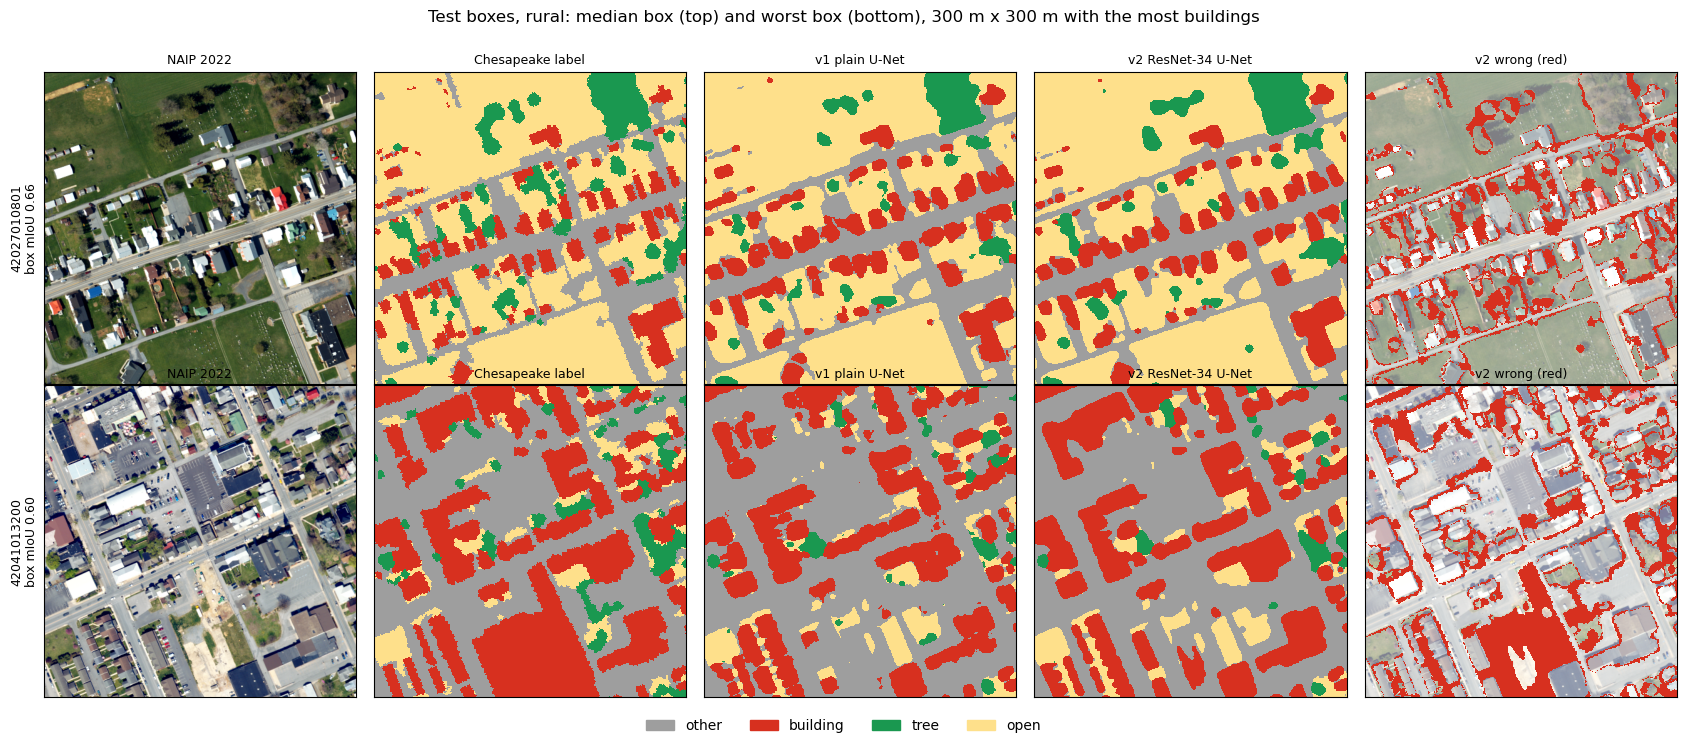

In [11]:
cmap = ListedColormap(["#9e9e9e", "#d7301f", "#1a9850", "#fee08b"])
W = 500   # 300 m x 300 m


def busiest(lab, w=W, step=100):
    """Corner of the w x w window with the most building pixels."""
    c = np.pad((lab == 1).astype(np.int32).cumsum(0).cumsum(1), ((1, 0), (1, 0)))
    best, rc = -1, (0, 0)
    for r in range(0, lab.shape[0] - w, step):
        for k in range(0, lab.shape[1] - w, step):
            v = c[r + w, k + w] - c[r, k + w] - c[r + w, k] + c[r, k]
            if v > best:
                best, rc = v, (r, k)
    return rc


def show(ax_row, img, lab, p1, p2, title):
    r, c = busiest(lab)
    sl = (slice(r, r + W), slice(c, c + W))
    rgb = np.moveaxis(img[:3], 0, -1)[sl].astype(float)
    lo, hi = np.percentile(rgb, [2, 98])
    err = np.where(lab[sl] == 255, np.nan, (p2[sl] != lab[sl]).astype(float))
    panels = [("NAIP 2022", None), ("Chesapeake label", lab[sl]), ("v1 plain U-Net", p1[sl]), ("v2 ResNet-34 U-Net", p2[sl]), ("v2 wrong (red)", err)]
    for a, (t, arr) in zip(ax_row, panels):
        if arr is None:
            a.imshow(np.clip((rgb - lo) / (hi - lo), 0, 1))
        elif t.startswith("v2 wrong"):
            a.imshow(np.clip((rgb - lo) / (hi - lo), 0, 1) * 0.5 + 0.5)
            a.imshow(np.ma.masked_where(~(arr == 1), arr), cmap=ListedColormap(["#d7301f"]), interpolation="nearest")
        else:
            a.imshow(np.ma.masked_equal(arr, 255), cmap=cmap, vmin=0, vmax=3, interpolation="nearest")
        a.set_title(t, fontsize=9); a.set_xticks([]); a.set_yticks([])
    ax_row[0].set_ylabel(title, fontsize=9)


for s in STRATA:
    picks = per_box[per_box.stratum == s].sort_values("miou")
    picks = [picks.GEOID.iloc[len(picks) // 2], picks.GEOID.iloc[0]]   # a middle box and the worst box
    fig, axes = plt.subplots(2, 5, figsize=(17, 7.4))
    for row, g in zip(axes, picks):
        img, lab, p1, p2 = keep[g]
        m = per_box.set_index("GEOID").miou[g]
        show(row, img, lab, p1, p2, f"{g}\nbox mIoU {m:.2f}")
    fig.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in cmap.colors], CLASSES, loc="lower center", ncol=4, frameon=False)
    fig.suptitle(f"Test boxes, {s}: median box (top) and worst box (bottom), 300 m x 300 m with the most buildings", y=0.99)
    plt.tight_layout(rect=(0, 0.04, 1, 0.97))
    plt.savefig(FIG / f"03_test_{s}.png", dpi=100)
    plt.show()

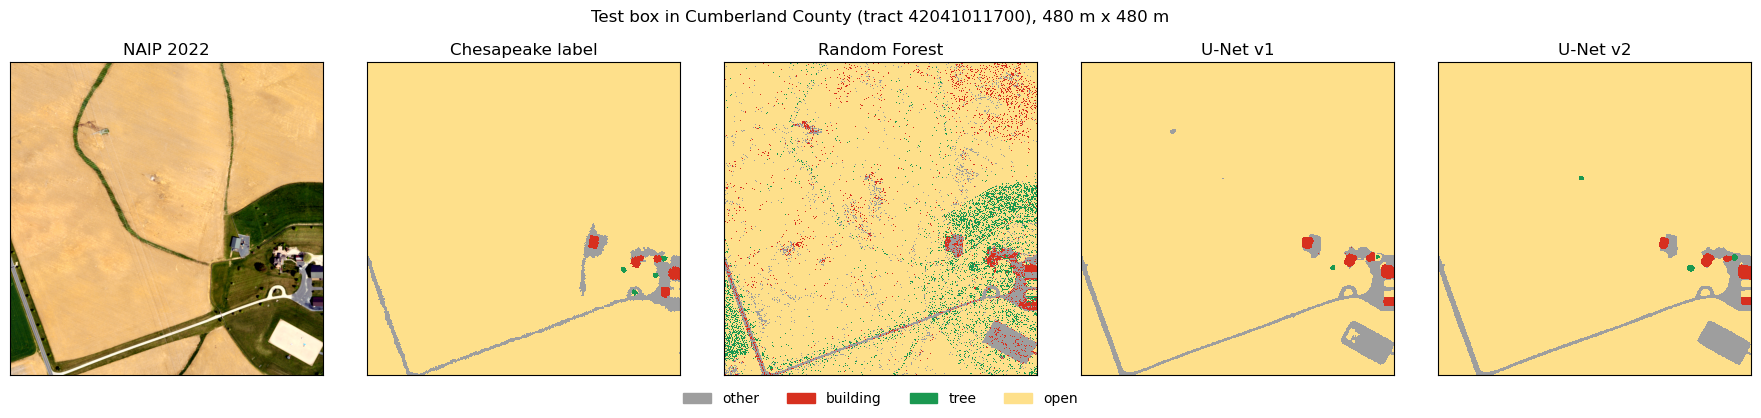

In [12]:
EX = "42041011700"   # suburban Cumberland box with houses (same as before)
img, lab, p1, p2 = keep[EX]
rfp = np.load(OUT / "6950_rf_test_pred.npz")[EX] if (OUT / "6950_rf_test_pred.npz").exists() else None
sl = (slice(600, 1400), slice(600, 1400))   # zoom 480 m x 480 m
rgb = np.moveaxis(img[:3], 0, -1)[sl].astype(float)
lo, hi = np.percentile(rgb, [2, 98])
panels = [("NAIP 2022", None), ("Chesapeake label", lab[sl])] + ([("Random Forest", rfp[sl])] if rfp is not None else []) + \
         [("U-Net v1", p1[sl]), ("U-Net v2", p2[sl])]
fig, axes = plt.subplots(1, len(panels), figsize=(3.6 * len(panels), 4.1))
for a, (t, arr) in zip(axes, panels):
    if arr is None:
        a.imshow(np.clip((rgb - lo) / (hi - lo), 0, 1))
    else:
        a.imshow(np.ma.masked_equal(arr, 255), cmap=cmap, vmin=0, vmax=3, interpolation="nearest")
    a.set_title(t); a.set_xticks([]); a.set_yticks([])
fig.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in cmap.colors], CLASSES, loc="lower center", ncol=4, frameon=False)
fig.suptitle(f"Test box in Cumberland County (tract {EX}), 480 m x 480 m", y=0.99)
plt.tight_layout(rect=(0, 0.06, 1, 0.97))
plt.savefig(FIG / "03_example_prediction.png", dpi=110)
plt.show()